# 09 - Model Explainability

This notebook explains the saved, sigmoid-calibrated hybrid model on the held-out test partition. It does not fit or tune a model or threshold. The test data is used only for final predictions and explanations. SHAP values are calculated for a reproducible sample of at most 200 test postings, including up to three examples from each prediction/error group. The saved app threshold is used to define those groups.

The selected model is a calibrated Linear SVM, not Logistic Regression, Random Forest, or XGBoost. Linear-model SHAP contributions below explain the underlying SVM decision margin, not calibrated risk percentages. Positive contributions move the margin toward the fraud class and negative contributions move it away. No feature proves that a posting is fraudulent.

## 1. Load the saved model and reproduce the untouched test split

The raw and processed rows are aligned and checked before recreating the original stratified 80/20 split. The calibrated app pipeline and saved decision threshold are loaded as-is.

In [1]:
import json
import re
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from sklearn.model_selection import train_test_split

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
elif PROJECT_DIR.name != "fake-job-detector" and (PROJECT_DIR / "fake-job-detector").is_dir():
    PROJECT_DIR = PROJECT_DIR / "fake-job-detector"

MODEL_PATH = PROJECT_DIR / "models" / "fake_job_detector.joblib"
METADATA_PATH = PROJECT_DIR / "models" / "fake_job_detector_metadata.json"
THRESHOLD_PATH = PROJECT_DIR / "models" / "model_threshold.json"
PROCESSED_PATH = PROJECT_DIR / "data" / "processed" / "processed_job_postings.csv"
RAW_PATH = PROJECT_DIR / "data" / "raw" / "DataSet.csv"
REPORT_PATH = PROJECT_DIR / "report" / "explainability_report.md"
CHART_PATH = PROJECT_DIR / "report" / "explainability_feature_importance.png"
for path in (MODEL_PATH, METADATA_PATH, THRESHOLD_PATH, PROCESSED_PATH, RAW_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Required explainability input not found: {path}")

model = joblib.load(MODEL_PATH)
with METADATA_PATH.open(encoding="utf-8") as file:
    model_metadata = json.load(file)
with THRESHOLD_PATH.open(encoding="utf-8") as file:
    threshold_config = json.load(file)

numeric_features = model_metadata["numeric_features"]
categorical_features = model_metadata["categorical_features"]
text_feature = model_metadata["text_feature"]
decision_threshold = float(threshold_config["selected_threshold"])
processed = pd.read_csv(
    PROCESSED_PATH,
    usecols=[text_feature, "fraudulent", *numeric_features],
    low_memory=False,
)
raw = pd.read_csv(RAW_PATH, low_memory=False).drop_duplicates().copy().reset_index(drop=True)
if len(raw) != len(processed):
    raise ValueError(f"Raw and processed row counts differ: {len(raw)} vs {len(processed)}")

text_columns = [column for column in ["title", "company_profile", "description", "requirements", "benefits"] if column in raw.columns]
if len(text_columns) != 5 or any(column not in raw.columns for column in categorical_features):
    raise ValueError("Required text or categorical feature columns are missing from the raw CSV.")
raw_view = raw[[*categorical_features, "fraudulent", *text_columns]].copy()
for column in raw_view.select_dtypes(include=["object", "string"]).columns:
    raw_view[column] = raw_view[column].replace(r"^\s*$", pd.NA, regex=True)

def clean_text(value):
    text = "" if pd.isna(value) else str(value)
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\b(?:https?://|www\.)\S+", " URL ", text, flags=re.IGNORECASE)
    text = re.sub(r"\b[\w.+%-]+@[\w.-]+\.[a-z]{2,}\b", " EMAIL ", text, flags=re.IGNORECASE)
    return re.sub(r"\s+", " ", text).strip()

rebuilt_text = raw_view[text_columns].fillna("").astype(str).agg(" ".join, axis=1).map(clean_text).to_numpy()
if not np.array_equal(rebuilt_text, processed[text_feature].fillna("").astype(str).to_numpy()):
    raise ValueError("Raw and processed text do not align row by row.")
labels = raw_view["fraudulent"].astype(str).str.strip().str.lower().to_numpy()
processed_labels = processed["fraudulent"].astype(str).str.strip().str.lower().to_numpy()
if not np.array_equal(labels, processed_labels):
    raise ValueError("Raw and processed labels do not align row by row.")
if set(labels) != {"f", "t"}:
    raise ValueError(f"Unexpected target labels: {sorted(set(labels))}")

X = processed[[text_feature, *numeric_features]].copy()
for column in categorical_features:
    X[column] = raw_view[column].reset_index(drop=True)
X = X[[text_feature, *categorical_features, *numeric_features]]
y = pd.Series(labels, index=X.index).map({"f": 0, "t": 1}).astype("int8")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
test_raw = raw_view.iloc[X_test.index].copy()
fraud_class_index = int(np.flatnonzero(model.classes_ == 1)[0])
fraud_probability = model.predict_proba(X_test)[:, fraud_class_index]
y_pred = (fraud_probability >= decision_threshold).astype("int8")
print(f"Saved model: {type(model).__name__}; test rows: {len(X_test):,}; selected app threshold: {decision_threshold:.2f}")
print("Raw/processed alignment verified; model was not fit and threshold was not tuned here.")

Saved model: CalibratedClassifierCV; test rows: 3,529; selected app threshold: 0.40
Raw/processed alignment verified; model was not fit and threshold was not tuned here.


## 2. Choose explanation examples and a bounded SHAP sample

For consistency with the application, predictions use the saved F1-selected threshold. The SHAP sample contains up to 150 random test rows plus three examples from each available true-positive, true-negative, false-positive, and false-negative group. The test sample is capped at 200 rows; no SHAP values are calculated for the rest of the test set.

In [2]:
test_results = test_raw.copy()
test_results["actual"] = y_test.to_numpy()
test_results["predicted"] = y_pred
test_results["fraud_probability"] = fraud_probability

groups = {
    "Correctly detected fraudulent": test_results[(test_results.actual == 1) & (test_results.predicted == 1)],
    "Correctly detected legitimate": test_results[(test_results.actual == 0) & (test_results.predicted == 0)],
    "False positives": test_results[(test_results.actual == 0) & (test_results.predicted == 1)],
    "False negatives": test_results[(test_results.actual == 1) & (test_results.predicted == 0)],
}
group_counts = pd.DataFrame({"Prediction group": list(groups), "Available test examples": [len(frame) for frame in groups.values()]})
display(group_counts)

selected_examples = {}
for group_name, frame in groups.items():
    selected_examples[group_name] = frame.sample(n=min(3, len(frame)), random_state=42)
selected_indices = [index for frame in selected_examples.values() for index in frame.index]
random_indices = X_test.sample(n=min(150, len(X_test)), random_state=42).index.tolist()
explain_indices = list(dict.fromkeys([*selected_indices, *random_indices]))[:200]
print(f"SHAP will explain {len(explain_indices)} test postings (maximum 200).")
for group_name, frame in selected_examples.items():
    if len(frame) < 3:
        print(f"Note: only {len(frame)} examples available for {group_name}; all available examples will be shown.")

,Prediction group,Available test examples
0,Correctly detected fraudulent,142
1,Correctly detected legitimate,3332
2,False positives,25
3,False negatives,30


SHAP will explain 162 test postings (maximum 200).


## 3. SHAP values for the calibrated linear model

The calibrated model is an ensemble of three fitted Linear SVM pipelines. Each pipeline has its own learned vocabulary, so SHAP is computed for each component on its own transformed sparse features and the contributions are aligned by feature name before averaging. A small training-only background sample defines the baseline. This explains the ensemble's average SVM decision margin; sigmoid calibration and averaging mean these additive contributions are not percentage-point changes in probability.

In [3]:
if not hasattr(model, "calibrated_classifiers_"):
    raise TypeError("Expected the saved calibrated model to expose its fitted component classifiers.")

X_explain = X_test.loc[explain_indices]
background_indices = X_train.sample(n=min(40, len(X_train)), random_state=42).index
X_background = X_train.loc[background_indices]
component_shap = []
component_feature_names = []
for component_number, calibrated_component in enumerate(model.calibrated_classifiers_, start=1):
    pipeline = calibrated_component.estimator
    classifier = pipeline.named_steps["classifier"]
    if not hasattr(classifier, "coef_"):
        raise TypeError(f"Component {component_number} is not a linear classifier with coefficients.")
    preprocessor = pipeline.named_steps["preprocessor"]
    feature_names = preprocessor.get_feature_names_out().astype(str)
    background_matrix = preprocessor.transform(X_background)
    explain_matrix = preprocessor.transform(X_explain)
    explainer = shap.LinearExplainer(
        (classifier.coef_, classifier.intercept_),
        background_matrix,
        feature_perturbation="interventional",
    )
    component_values = explainer(explain_matrix).values
    if component_values.ndim == 3:
        component_values = component_values[:, :, 0]
    component_shap.append(np.asarray(component_values, dtype=np.float64))
    component_feature_names.append(feature_names)
    print(f"Explained component {component_number}/{len(model.calibrated_classifiers_)}: {len(feature_names):,} features")

all_feature_names = sorted(set().union(*(set(names) for names in component_feature_names)))
feature_to_column = {name: index for index, name in enumerate(all_feature_names)}
mean_shap = np.zeros((len(explain_indices), len(all_feature_names)), dtype=np.float64)
for values, names in zip(component_shap, component_feature_names):
    columns = [feature_to_column[name] for name in names]
    mean_shap[:, columns] += values / len(component_shap)

global_importance = pd.DataFrame({
    "Feature": all_feature_names,
    "Mean absolute SHAP (SVM margin)": np.mean(np.abs(mean_shap), axis=0),
    "Mean SHAP (SVM margin)": np.mean(mean_shap, axis=0),
}).sort_values("Mean absolute SHAP (SVM margin)", ascending=False)
print("Top 20 global features by mean absolute SHAP value:")
display(global_importance.head(20).style.format({
    "Mean absolute SHAP (SVM margin)": "{:.5f}",
    "Mean SHAP (SVM margin)": "{:.5f}",
}))

scam_indicator_names = [name for name in all_feature_names if "raw__contains_" in name]
scam_indicator_importance = global_importance[global_importance["Feature"].isin(scam_indicator_names)].copy()
print("Scam-indicator features ranked by mean absolute SHAP value:")
display(scam_indicator_importance.head(20).style.format({
    "Mean absolute SHAP (SVM margin)": "{:.5f}",
    "Mean SHAP (SVM margin)": "{:.5f}",
}))

<PYTHON_ENV>\Lib\site-packages\shap\explainers\_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)


Explained component 1/3: 10,390 features


<PYTHON_ENV>\Lib\site-packages\shap\explainers\_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)


Explained component 2/3: 10,390 features


<PYTHON_ENV>\Lib\site-packages\shap\explainers\_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)


Explained component 3/3: 10,377 features
Top 20 global features by mean absolute SHAP value:


,Feature,Mean absolute SHAP (SVM margin),Mean SHAP (SVM margin)
427,numeric__raw__word_count,0.72971,0.08895
412,numeric__raw__character_count,0.71897,-0.08127
100,categorical__has_company_logo_t,0.17780,-0.01794
102,categorical__has_questions_t,0.14663,0.02022
423,numeric__raw__missing_company_profile,0.13337,-0.02216
355,categorical__required_education_Bachelor's Degree,0.13114,0.00878
101,categorical__has_questions_f,0.11323,-0.01562
367,categorical__required_experience_Associate,0.07103,0.00257
77,categorical__function_Health Care Provider,0.06100,0.02138
148,categorical__industry_Internet,0.05990,0.01312


Scam-indicator features ranked by mean absolute SHAP value:


,Feature,Mean absolute SHAP (SVM margin),Mean SHAP (SVM margin)
419,numeric__raw__contains_work_from_home,0.01173,-0.00411
417,numeric__raw__contains_urgent_language,0.00220,0.00001
416,numeric__raw__contains_no_experience,0.00210,0.00210
418,numeric__raw__contains_whatsapp_or_telegram,0.00000,0.00000
413,numeric__raw__contains_cryptocurrency_payment,0.00000,0.00000
414,numeric__raw__contains_easy_money,0.00000,0.00000
415,numeric__raw__contains_fee_request,0.00000,0.00000


## 4. Global feature-importance chart

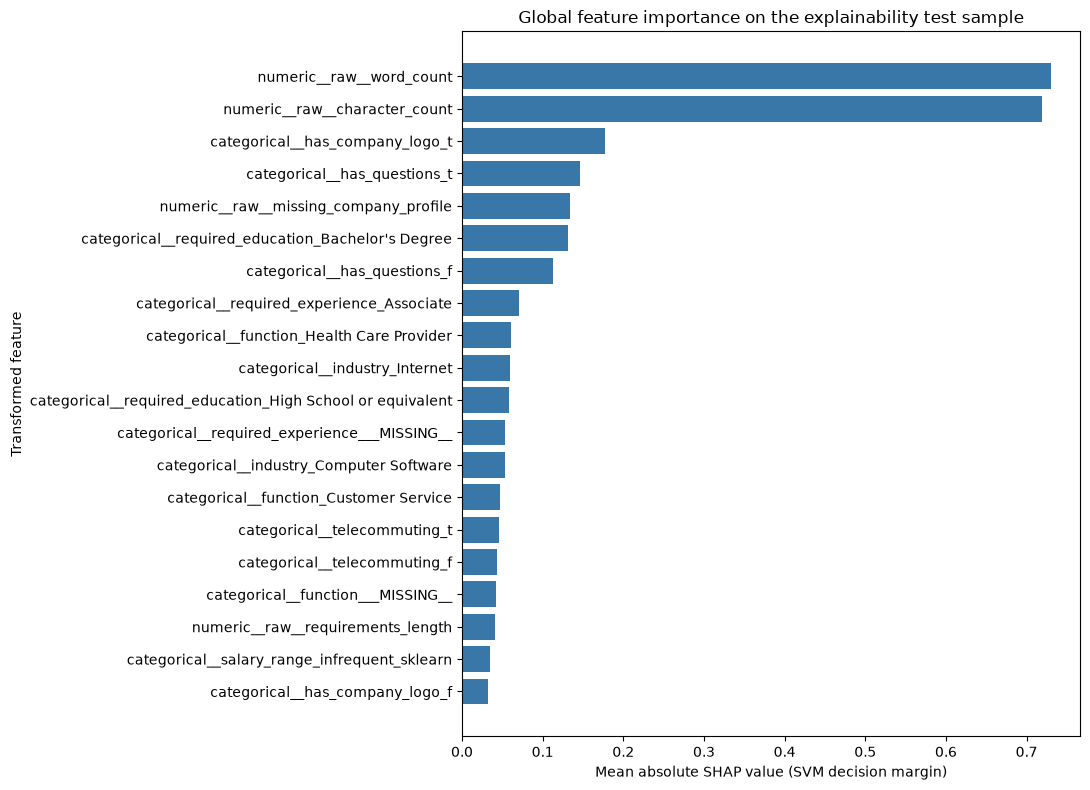

Saved feature-importance chart to <PROJECT_ROOT>\report\explainability_feature_importance.png


In [4]:
top_chart = global_importance.head(20).sort_values("Mean absolute SHAP (SVM margin)")
plt.figure(figsize=(11, 8))
plt.barh(top_chart["Feature"], top_chart["Mean absolute SHAP (SVM margin)"], color="#3977a8")
plt.xlabel("Mean absolute SHAP value (SVM decision margin)")
plt.ylabel("Transformed feature")
plt.title("Global feature importance on the explainability test sample")
plt.tight_layout()
CHART_PATH.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(CHART_PATH, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved feature-importance chart to {CHART_PATH}")

## 5. Local explanations for the requested examples

Each example lists the largest positive and negative SHAP contributions to the average SVM margin. Positive terms move the margin toward the model's fraud class; negative terms move it toward the legitimate class. They describe model behavior for this posting only and are not proof of fraud or legitimacy.

In [5]:
explain_row_for_index = {index: position for position, index in enumerate(explain_indices)}
local_records = []
local_report_sections = []
for group_name, frame in selected_examples.items():
    local_report_sections.append(f"### {group_name}\n")
    if frame.empty:
        local_report_sections.append("No examples of this type were present in the test split.\n")
        continue
    for example_number, (row_index, row) in enumerate(frame.iterrows(), start=1):
        shap_row = mean_shap[explain_row_for_index[row_index]]
        positive_positions = np.argsort(shap_row)[-5:][::-1]
        negative_positions = np.argsort(shap_row)[:5]
        positives = [(all_feature_names[position], float(shap_row[position])) for position in positive_positions if shap_row[position] > 0]
        negatives = [(all_feature_names[position], float(shap_row[position])) for position in negative_positions if shap_row[position] < 0]
        title = str(row.get("title", "(title unavailable)"))
        preview = re.sub(r"\s+", " ", str(row.get("description", "") or ""))[:320]
        local_records.append({
            "Group": group_name,
            "Example": example_number,
            "Title": title,
            "Actual label": "fraud" if int(row.actual) == 1 else "legitimate",
            "Predicted label": "fraud" if int(row.predicted) == 1 else "legitimate",
            "Fraud probability": float(row.fraud_probability),
            "Largest positive contributions": positives,
            "Largest negative contributions": negatives,
        })
        local_report_sections.append(
            f"#### Example {example_number}: {title}\n"
            f"- Actual: {'fraud' if int(row.actual) == 1 else 'legitimate'}; "
            f"predicted: {'fraud' if int(row.predicted) == 1 else 'legitimate'}; "
            f"calibrated fraud risk: {row.fraud_probability:.1%}.\n"
            f"- Posting description preview: {preview or '(empty)'}\n"
            f"- Contributions moving the SVM margin toward fraud: "
            f"{'; '.join(f'{name} ({value:+.4f})' for name, value in positives) or 'none among the top features'}.\n"
            f"- Contributions moving the SVM margin away from fraud: "
            f"{'; '.join(f'{name} ({value:+.4f})' for name, value in negatives) or 'none among the top features'}.\n"
        )

local_explanations = pd.DataFrame(local_records)
display(local_explanations[["Group", "Example", "Title", "Actual label", "Predicted label", "Fraud probability"]])
print("Local contributions are in the generated report; positive/negative signs refer to the SVM margin, not probability points.")

,Group,Example,Title,Actual label,Predicted label,Fraud probability
0,Correctly detected fraudulent,1,Cruise Staff Wanted *URGENT*,fraud,fraud,0.974894
1,Correctly detected fraudulent,2,Director of Engineering,fraud,fraud,0.991852
2,Correctly detected fraudulent,3,RECEPTIONIST / DATA ENTRY / OFFICE CLERK,fraud,fraud,0.955962
3,Correctly detected legitimate,1,Manufacturing Technician: Selective Laser Sint...,legitimate,legitimate,0.000220
4,Correctly detected legitimate,2,Production Manager,legitimate,legitimate,0.000285
5,Correctly detected legitimate,3,ACTIONSCRIPT DEVELOPER,legitimate,legitimate,0.001583
6,False positives,1,Payroll Clerk $20/hr,legitimate,fraud,0.723935
7,False positives,2,Tax Clerk,legitimate,fraud,0.701596
8,False positives,3,Part Time Ground representative,legitimate,fraud,0.775705
9,False negatives,1,Data Center Migration App Lead for FULL-TIME O...,fraud,legitimate,0.008461


Local contributions are in the generated report; positive/negative signs refer to the SVM margin, not probability points.


## 6. Write the explainability report

The report includes the leading global features, ranked scam indicators, per-example local contributions, and a link to the importance chart. Values describe model associations on this dataset; they do not establish that any single posting or feature is fraudulent.

In [6]:
model_type = type(model.calibrated_classifiers_[0].estimator.named_steps["classifier"]).__name__
model_specific_lines = []
if model_type == "LogisticRegression":
    classifier = model.calibrated_classifiers_[0].estimator.named_steps["classifier"]
    names = model.calibrated_classifiers_[0].estimator.named_steps["preprocessor"].get_feature_names_out()
    coefficients = classifier.coef_[0]
    model_specific_lines.extend([
        "The saved base estimator is Logistic Regression. Most positive TF-IDF coefficients:",
        *[f"- `{names[i]}`: {coefficients[i]:.5f}" for i in np.argsort(coefficients)[-10:][::-1]],
        "Most negative TF-IDF coefficients:",
        *[f"- `{names[i]}`: {coefficients[i]:.5f}" for i in np.argsort(coefficients)[:10]],
    ])
elif model_type in {"RandomForestClassifier", "XGBClassifier"}:
    classifier = model.calibrated_classifiers_[0].estimator.named_steps["classifier"]
    names = model.calibrated_classifiers_[0].estimator.named_steps["preprocessor"].get_feature_names_out()
    importances = getattr(classifier, "feature_importances_", None)
    if importances is not None:
        most_important = np.argsort(importances)[-20:][::-1]
        model_specific_lines.extend(["Tree-model feature importance (first calibrated component):", *[f"- `{names[i]}`: {importances[i]:.5f}" for i in most_important]])
elif model_type == "LinearSVC":
    model_specific_lines.append("The saved base estimator is Linear SVM; SHAP margin contributions are used instead of Logistic Regression coefficients or tree feature importance.")
else:
    model_specific_lines.append(f"Base estimator: `{model_type}`. Global and local explanations are reported using the available linear SHAP workflow only when supported by the fitted estimator.")

global_lines = [
    f"- `{row.Feature}`: mean |SHAP| = {row._1:.5f}; mean signed SHAP = {row._2:+.5f}"
    for row in global_importance.head(20).itertuples(index=False)
]
scam_lines = [
    f"- `{row.Feature}`: mean |SHAP| = {row._1:.5f}; mean signed SHAP = {row._2:+.5f}"
    for row in scam_indicator_importance.head(20).itertuples(index=False)
] or ["No transformed scam-indicator features were found in the global explanation."]
report_text = "\n".join([
    "# Model Explainability Report",
    "",
    "## Scope and method",
    "",
    f"- Saved app model: calibrated `{model_type}` ensemble; no fitting or threshold tuning was performed in this notebook.",
    f"- Held-out test rows: {len(X_test):,}; SHAP-explained rows: {len(explain_indices):,}; sampled training background rows: {len(background_indices):,}.",
    f"- Prediction threshold: {decision_threshold:.2f} from `models/model_threshold.json`.",
    "- Raw and processed rows, target labels, and cleaned text were checked for row-by-row alignment before the original stratified 80/20 split was reproduced.",
    "- SHAP values are averaged across the three fitted Linear SVM components and describe the underlying decision margin, not calibrated probability points.",
    "",
    "## Simple interpretation",
    "",
    "A positive SHAP contribution moves the model's SVM margin toward predicting fraud; a negative contribution moves it away. A larger absolute value means a stronger contribution relative to the sampled background. The calibrated probability combines component margins through sigmoid calibration, so an individual margin contribution is not a fixed percentage-point change in risk. These associations explain model behavior, not cause or proof: one feature cannot establish that a job posting is fraudulent or legitimate.",
    "",
    *model_specific_lines,
    "",
    "## Global feature importance",
    "",
    "Top 20 features by mean absolute SHAP value on the test sample:",
    *global_lines,
    "",
    "### Scam-indicator features",
    "",
    "Ranked by mean absolute SHAP contribution; the signed mean indicates the average direction in SVM-margin units:",
    *scam_lines,
    "",
    f"![Global feature importance](./{CHART_PATH.name})",
    "",
    "## Local explanations",
    "",
    "Examples were selected from test predictions made using the saved threshold. Positive and negative contributions refer to the average SVM decision margin, not calibrated percentage points. Titles and short description excerpts are included to identify each example; interpret them carefully because feature associations are not proof.",
    "",
    *local_report_sections,
    "## Limitations",
    "",
    "The global rankings depend on this model, dataset, and sampled background/test postings. Correlated words or features can share attribution, and transformed one-hot/text features may be less intuitive than the original posting. SHAP describes how this fitted model uses its inputs; it does not establish causation, fairness, generalization, or the truth of a fraud claim.",
    "",
])
REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)
REPORT_PATH.write_text(report_text, encoding="utf-8")
print(f"Saved explainability report to {REPORT_PATH}")
print(f"Saved global feature-importance chart to {CHART_PATH}")

Saved explainability report to <PROJECT_ROOT>\report\explainability_report.md
Saved global feature-importance chart to <PROJECT_ROOT>\report\explainability_feature_importance.png
